# ERA V5 Session 10 - making a small model tell the truth about itself

Six things, in order:

1. every tensor shape in one training step, with the meaning of every axis
2. one gradient verified by hand against `backward()`
3. gradient accumulation broken on purpose, and the control that proves it
4. the grad norm logged every step, and a step where it moved before the loss did
5. MFU measured against a benchmarked peak, and where the gap to 40% goes
6. `0.1` written out in fp32, bf16 and fp8 E4M3, bit by bit

The heavy experiments live in `src/` and write JSON to `artifacts/`. This
notebook reads those artifacts and re-derives the cheap parts live. Run
`python src/run_all.py` first if `artifacts/` is empty.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import torch
from common import *

def art(name):
    return json.loads((ROOT / "artifacts" / name).read_text())

print("torch", torch.__version__, "| cuda", torch.cuda.is_available())

torch 2.13.0+cu130 | cuda False


## The model

A nanoGPT-shaped decoder, small enough that a whole experiment finishes on one
CPU core. The config is chosen so that `B=8`, `T=64`, `V=65`, `head_dim=32`,
`C=128`, `3C=384` and `4C=512` are all different numbers. That is not
cosmetic: while writing Task 1 the first version of the axis labeller inferred
meaning from the size, and confidently labelled the *input* axis of every
weight matrix as "sequence position", because `block_size` happened to equal
`n_embd`. Distinct sizes make that class of mistake impossible to hide.

In [2]:
_, tok, ids = load_corpus()
cfg = GPTConfig(vocab_size=tok.vocab_size, block_size=64)
model = build_model(cfg)
print(f"{model.n_params():,} parameters, vocab {tok.vocab_size}, "
      f"{cfg.n_layer} layers, {cfg.n_head} heads, n_embd {cfg.n_embd}")

809,856 parameters, vocab 65, 4 layers, 4 heads, n_embd 128


## Task 1 - every tensor in the step

Parameters, activations, gradients, optimizer state. The axis meanings are *declared* symbolically and then asserted against the real tensor, so a wrong label raises instead of printing.

In [3]:
t1 = art("t1_shapes.json")
print(f"{t1['totals']['n_param_tensors']} parameter tensors, "
      f"{t1['totals']['n_params']:,} scalars")
print(f"{t1['totals']['n_traced_activations']} traced activations")
print(f"{t1['totals']['n_optimizer_state_tensors']} Adam state tensors "
      f"(2 per parameter tensor)")
print(f"lm_head.weight IS wte.weight: {t1['totals']['lm_head_shares_storage_with_wte']}")
print(f"all {t1['totals']['n_blocks_traced']} blocks traced, identical shapes: "
      f"{t1['totals']['all_blocks_have_identical_activation_shapes']}")
print()
for k, v in t1["parameters_by_layer"].items():
    print(f"  {k:<14}{v['n_tensors']:>3} tensors {v['n_params']:>9,} params")

52 parameter tensors, 809,856 scalars
22 traced activations
104 Adam state tensors (2 per parameter tensor)
lm_head.weight IS wte.weight: True
all 4 blocks traced, identical shapes: True

  top-level       4 tensors    16,768 params
  block 0        12 tensors   198,272 params
  block 1        12 tensors   198,272 params
  block 2        12 tensors   198,272 params
  block 3        12 tensors   198,272 params


In [4]:
for a in t1["activations"]:
    shape = tuple(a["shape"]) if a["shape"] else "()"
    print(f"{a['name']:<24}{str(shape)}")
    for g in a["axes"]:
        print(f"      {g}")

input_ids               (8, 64)
      8: B - independent sequences in this micro-batch
      64: T - sequence positions (context length used by this batch)
positions               (64,)
      64: T - sequence positions (context length used by this batch)
token_embeddings        (8, 64, 128)
      8: B - independent sequences in this micro-batch
      64: T - sequence positions (context length used by this batch)
      128: C = n_embd - residual-stream channels
position_embeddings     (64, 128)
      64: T - sequence positions (context length used by this batch)
      128: C = n_embd - residual-stream channels
residual_stream         (8, 64, 128)
      8: B - independent sequences in this micro-batch
      64: T - sequence positions (context length used by this batch)
      128: C = n_embd - residual-stream channels
logits                  (8, 64, 65)
      8: B - independent sequences in this micro-batch
      64: T - sequence positions (context length used by this batch)
      65: V =

The 16 bytes per parameter that a step actually costs, and what that means at the scale the course is heading for:

In [5]:
m = t1["memory_per_param_bytes"]
for k in ("bf16_weight","bf16_grad","fp32_master_weight",
          "adam_exp_avg_fp32","adam_exp_avg_sq_fp32","total"):
    print(f"  {k:<22}{m[k]:>3} bytes")
print(f"\nthis model's step state: {m['this_model_state_MiB']:.2f} MiB")
print(f"a 120B checkpoint on the same recipe: "
      f"{m['extrapolated_checkpoint_TiB_at_120B']:.2f} TiB")

  bf16_weight             2 bytes
  bf16_grad               2 bytes
  fp32_master_weight      4 bytes
  adam_exp_avg_fp32       4 bytes
  adam_exp_avg_sq_fp32    4 bytes
  total                  16 bytes

this model's step state: 12.36 MiB
a 120B checkpoint on the same recipe: 1.75 TiB


## Task 2 - verify a gradient by hand

Nudge a weight, see how the loss actually moved, compare with what `backward()`
said. Done live below with a central difference, which has error O(h^2) instead
of O(h) and can therefore actually reach several decimals.

In [6]:
import math
set_seed(1337)
m64 = build_model(GPTConfig(vocab_size=tok.vocab_size, block_size=32),
                  dtype=torch.float64)
gen = torch.Generator().manual_seed(0)
x, y = uniform_batch(ids, 4, 32, gen)
_, loss = m64(x, y); base = loss.item()
m64.zero_grad(set_to_none=True); loss.backward()

# the tied embedding: perturbing it moves BOTH the input embedding and the
# output logits, so this probe fails unless autograd summed both paths
p = dict(m64.named_parameters())["wte.weight"]; idx = 731
analytic = p.grad.view(-1)[idx].item()

def loss_at(delta):
    with torch.no_grad():
        w = p.view(-1)[idx].item()
        p.view(-1)[idx] = w + delta
        _, l = m64(x, y)
        p.view(-1)[idx] = w
    return l.item()

print(f"base loss        {base:.15f}")
print(f"autograd says    {analytic:.15f}\n")
print(f"{'h':>8}{'central difference':>24}{'matching digits':>18}")
for h in (1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7):
    fd = (loss_at(+h) - loss_at(-h)) / (2*h)
    d = -math.log10(abs(fd - analytic) / abs(analytic))
    print(f"{h:>8.0e}{fd:>24.15f}{d:>18.2f}")

base loss        4.208409153374923
autograd says    -0.003249439288662

       h      central difference   matching digits
   1e-02      -0.003250010623201              3.75


   1e-03      -0.003249445009956              5.75


   1e-04      -0.003249439348707              7.73
   1e-05      -0.003249439295416              8.68
   1e-06      -0.003249439384234              7.53
   1e-07      -0.003249440716502              6.36


The same check run in fp32 tells a different story, and that difference is the
finding rather than a nuisance. Below, `fp64` reaches 8-10 significant digits;
`fp32` plateaus in the low single digits no matter how small `h` gets, because
`L(w+h)` and `L(w-h)` are two nearly-equal numbers being subtracted and almost
every significant digit cancels. `backward()` is not wrong there. The
measurement is. This is the same precision argument Task 6 makes with bits.

In [7]:
t2 = art("t2_finite_diff.json")
h2 = t2["headline"]
print(f"fp64: worst {h2['fp64_min_matching_digits']:.2f} digits, "
      f"median {h2['fp64_median_matching_digits']:.2f}")
print(f"fp32: worst {h2['fp32_min_matching_digits']:.2f} digits, "
      f"median {h2['fp32_median_matching_digits']:.2f}\n")
print(f"{'parameter':<30}{'fp64 digits':>13}{'fp32 digits':>13}")
for a, b in zip(t2["fp64"]["results"], t2["fp32"]["results"]):
    print(f"{a['param']:<30}{a['best_matching_digits']:>13.2f}"
          f"{b['best_matching_digits']:>13.2f}")

fp64: worst 8.51 digits, median 9.44
fp32: worst 0.39 digits, median 2.67

parameter                       fp64 digits  fp32 digits
wte.weight                             8.68         2.67
wpe.weight                             9.44         3.11
blocks.0.attn.c_attn.weight            8.63         1.61
blocks.0.attn.c_proj.bias              9.48         3.76
blocks.2.mlp.c_fc.weight               8.79         2.67
blocks.3.mlp.c_proj.weight            10.12         2.28
blocks.1.ln_1.weight                   8.51         0.39
ln_f.weight                            9.91         1.09


One more check, on the harness rather than on autograd. Everything above is my
finite-difference code checking PyTorch; if that code has a sign error or leaves
a weight perturbed, it could agree with autograd for the wrong reason.
`torch.autograd.gradcheck` is an implementation I did not write, so running it
on the same model checks my harness.

In [8]:
gc = t2["gradcheck_corroboration"]
for r in gc["results"]:
    print(f"  {r['param']:<28}{r['numel']:>5} scalars   passed: {r['passed']}")
print(f"\nall passed: {gc['all_passed']}")

  blocks.0.mlp.c_fc.bias        128 scalars   passed: True
  blocks.1.ln_1.weight           32 scalars   passed: True
  blocks.0.attn.c_proj.bias      32 scalars   passed: True
  ln_f.bias                      32 scalars   passed: True

all passed: True


## Task 3 - break gradient accumulation on purpose

    correct : sum_i (sum of per-token losses in i) / sum_i n_valid_i
    broken  : mean_i ( mean of per-token losses in i )

Identical whenever every micro-batch scores the same number of tokens, which is
why this sat in mainstream trainers until 2024: packed fixed-length pretraining
never triggers it. Four arms were run - ragged and uniform, correct and broken.
The uniform pair is the control; if those two curves were not identical, the
ragged gap would be measuring something else entirely.

In [9]:
t3 = art("t3_accum.json")
s0 = t3["step0_gradient_comparison"]
print("step 0, against a reference gradient computed in one shot with no accumulation:")
for regime in ("ragged", "uniform"):
    e = s0[regime]
    print(f"\n  {regime}: valid tokens per micro-batch "
          f"{e['valid_tokens_per_micro_batch']}")
    for mode in ("correct", "broken"):
        print(f"    {mode:<8} relative L2 error "
              f"{e[mode]['rel_l2_error_vs_reference']:.3e}   "
              f"cosine {e[mode]['cosine_similarity_vs_reference']:.9f}")

step 0, against a reference gradient computed in one shot with no accumulation:

  ragged: valid tokens per micro-batch [46, 90, 59, 65]
    correct  relative L2 error 2.044e-16   cosine 1.000000000
    broken   relative L2 error 1.100e-01   cosine 0.993941130

  uniform: valid tokens per micro-batch [256, 256, 256, 256]
    correct  relative L2 error 2.972e-16   cosine 1.000000000
    broken   relative L2 error 2.972e-16   cosine 1.000000000


In [10]:
h3 = t3["headline"]
print(f"held-out loss after 400 steps")
print(f"  ragged  correct {h3['ragged_final_correct']:.6f}   "
      f"broken {h3['ragged_final_broken']:.6f}   gap {h3['ragged_final_gap']:+.6f}")
print(f"  uniform correct {h3['uniform_final_correct']:.6f}   "
      f"broken {h3['uniform_final_broken']:.6f}   gap {h3['uniform_final_gap']:+.6f}")
print(f"\nmean gap over the second half: {h3['ragged_mean_gap_last_half']:.6f}")
print(f"gap positive at this fraction of eval points: "
      f"{h3['ragged_gap_positive_fraction']:.0%}")

held-out loss after 400 steps
  ragged  correct 2.468379   broken 2.481853   gap +0.013474
  uniform correct 2.381348   broken 2.381348   gap +0.000000

mean gap over the second half: 0.018047
gap positive at this fraction of eval points: 100%


The size mismatch is the interesting part. An **11%** error in the gradient
produces a **0.018** gap in the loss. Loud where nobody was looking, nearly
silent where everybody was. That is the whole explanation for how it survived
so long.

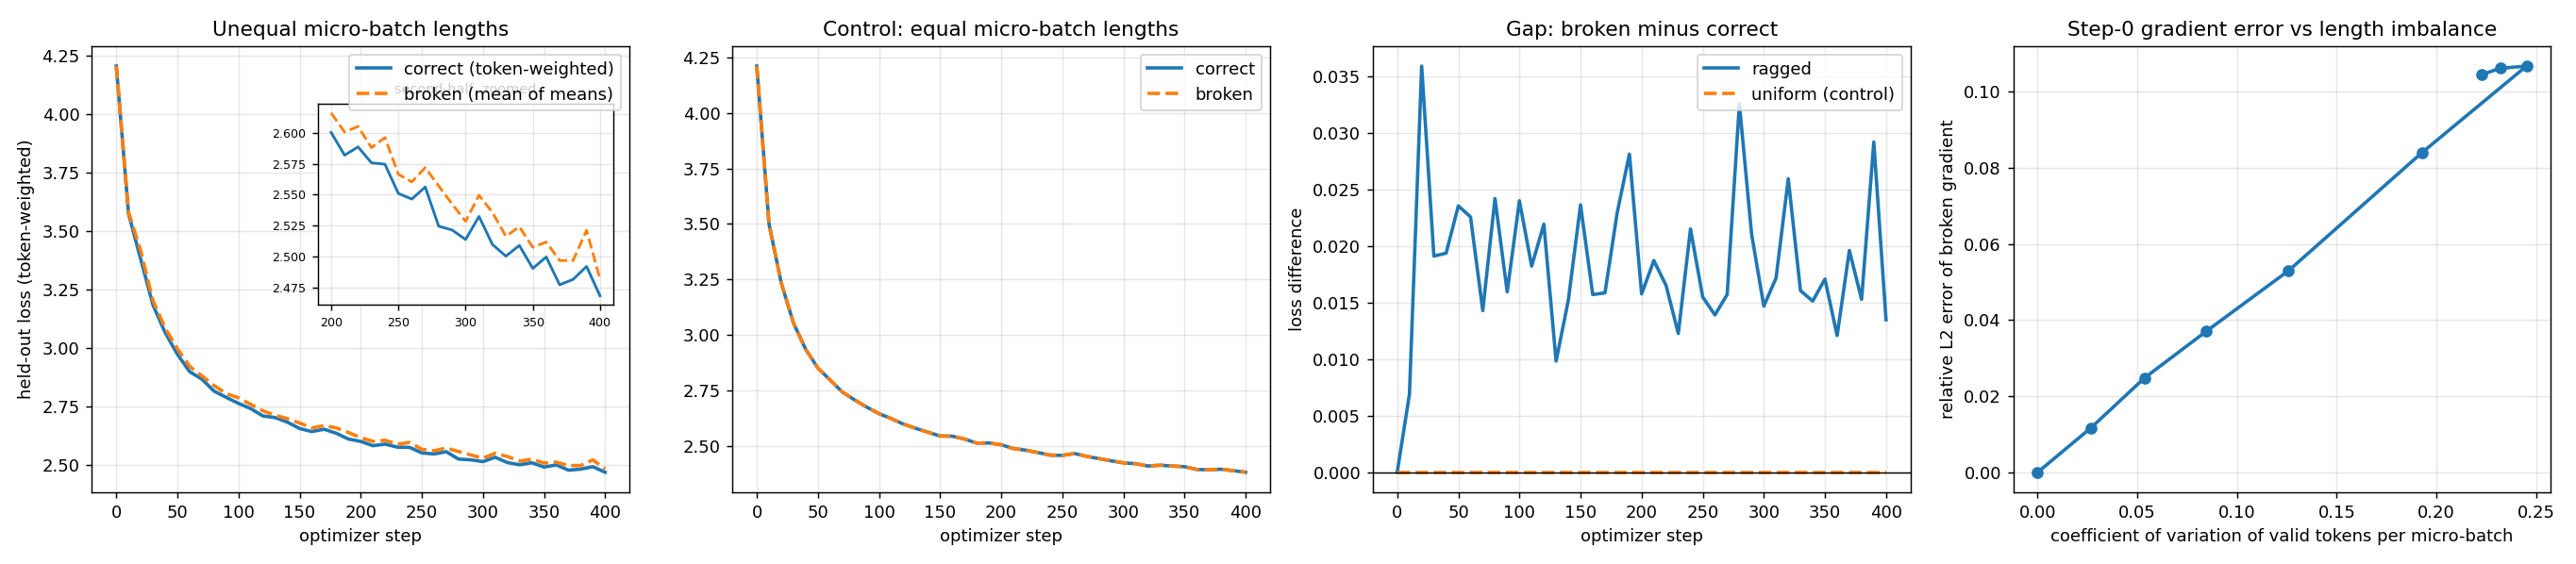

In [11]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "figures" / "t3_accum.png")))

## Task 4 - the grad norm moves first

A four-step window of out-of-distribution text is injected at step 200. The
text is Sanskrit in Harvard-Kyoto transliteration, which is pure ASCII: every
character is already in the Shakespeare vocabulary, so the tokenizer genuinely
cannot tell the two apart. That is the session's Sanskrit-into-Hindi example
made measurable - familiar characters, wholly unfamiliar distribution, and the
only thing that notices is the gradient.

In [12]:
t4 = art("t4_gradnorm.json")
d = t4["norm_vs_loss_detectability"]
print(f"at the injection step {d['step']}, both series z-scored against their "
      f"own trailing 50-step baseline:\n")
print(f"  grad norm      z = {d['z_grad']:7.2f}   fires at Z=4? "
      f"{d['norm_would_have_fired']}")
print(f"  loss change    z = {d['z_dloss']:7.2f}   fires at Z=4? "
      f"{d['loss_would_have_fired']}")
print(f"\n  a monitor watching the loss sees nothing. "
      f"detectability ratio {d['detectability_ratio']:.1f}x")
ir = t4["injection_response"]
print(f"\n  grad norm {ir['grad_norm_before_injection']:.3f} -> "
      f"{ir['grad_norm_at_injection']:.3f} "
      f"({ir['grad_norm_spike_multiple']:.2f}x)")
print(f"  held-out loss peaks at +{t4['headline']['peak_excess_loss_noclip']:.4f} "
      f"over clean, {t4['headline']['steps_from_injection_end_to_peak_loss']} steps "
      f"after the last bad batch")

at the injection step 200, both series z-scored against their own trailing 50-step baseline:

  grad norm      z =   10.61   fires at Z=4? True
  loss change    z =    1.09   fires at Z=4? False

  a monitor watching the loss sees nothing. detectability ratio 9.7x

  grad norm 1.411 -> 4.075 (2.89x)
  held-out loss peaks at +0.2896 over clean, 2 steps after the last bad batch


And one with no injection at all. The clean run produces a lead event at
**step 162** with a lag of **4**: the grad norm sits at 1.44x its trailing
median while the loss change is unremarkable, and the loss does not cross the
threshold until four steps later. It is below the primary Z=4 bar and is
reported at the secondary Z=3.0 threshold, but it is the more interesting of the
two, because nothing was done to the run to produce it.

In [13]:
e = t4["lead_events_at_secondary_threshold"]["clean/noclip"]
print(f"clean run, step {e['step']}, lag {e['lag_steps']} steps")
print(f"  grad norm {e['grad_norm_at_step']:.3f} = "
      f"{e['grad_norm_multiple_of_trailing_median']:.2f}x its trailing median")
print(f"  z_grad {e['z_grad']:.2f}   z_dloss now {e['z_dloss_same_step']:.2f}"
      f"   z_dloss at +{e['lag_steps']} {e['z_dloss_at_lag']:.2f}")
print("\nheld-out loss around that step:")
for k, v in e["eval_loss_window"].items():
    print(f"  step {k}: {v:.6f}")

clean run, step 162, lag 4 steps
  grad norm 2.059 = 1.44x its trailing median
  z_grad 3.61   z_dloss now 1.38   z_dloss at +4 3.05

held-out loss around that step:
  step 159: 2.705324
  step 160: 2.709369
  step 161: 2.713622
  step 162: 2.716714
  step 163: 2.710035
  step 164: 2.703806
  step 165: 2.711483
  step 166: 2.720283
  step 167: 2.724165
  step 168: 2.718965


### How long the damage takes to show

Both distances are reported, because quoting only the first would flatter the
result: the injection window is four steps wide, so the honest answer to "how
long after the last bad batch" is the smaller number.

In [14]:
la = t4["injection_response"]["lag_accounting"]
print(f"injection window        steps {la['injection_window'][0]}-{la['injection_window'][1]}")
print(f"peak held-out loss      step {la['peak_loss_step']}")
print(f"from injection START    {la['steps_from_injection_START_to_peak']} steps")
print(f"from injection END      {la['steps_from_injection_END_to_peak']} steps")

injection window        steps 200-203
peak held-out loss      step 205
from injection START    5 steps
from injection END      2 steps


Two results I did not go looking for, kept because they are what the data says.

**In healthy training the relationship runs the other way.** The correlation
between the grad-norm anomaly and the next step's loss change is *negative* in
the clean arm. A large gradient in ordinary training means the batch was
informative and the loss is about to drop. "Grad norm leads loss" is a property
of anomalies, not of training.

**Clipping helps, then stops helping.** Tightening the threshold below 1.0 buys
nothing at all. Clipping caps the gradient's magnitude but leaves its direction
alone, and Adam already rescales per parameter, so what is left is directional
damage that no threshold can remove.

In [15]:
print("correlation between grad-norm z and next-step loss change:")
for k, v in t4["headline"]["xcorr_lag1_r"].items():
    print(f"  {k:<16}r = {v:+.3f}")
print("\npeak held-out loss excess after the injection, by clip threshold:")
for r in t4["mitigation_sweep"]:
    lab = "none" if r["clip"] is None else str(r["clip"])
    print(f"  clip {lab:<6}{r['peak_excess_loss_vs_clean']:.4f}")

correlation between grad-norm z and next-step loss change:
  clean/noclip    r = -0.391
  inject/noclip   r = +0.150
  inject/clip1.0  r = +0.229

peak held-out loss excess after the injection, by clip threshold:
  clip none  0.2896
  clip 2.0   0.2427
  clip 1.0   0.1965
  clip 0.5   0.1964
  clip 0.25  0.1964


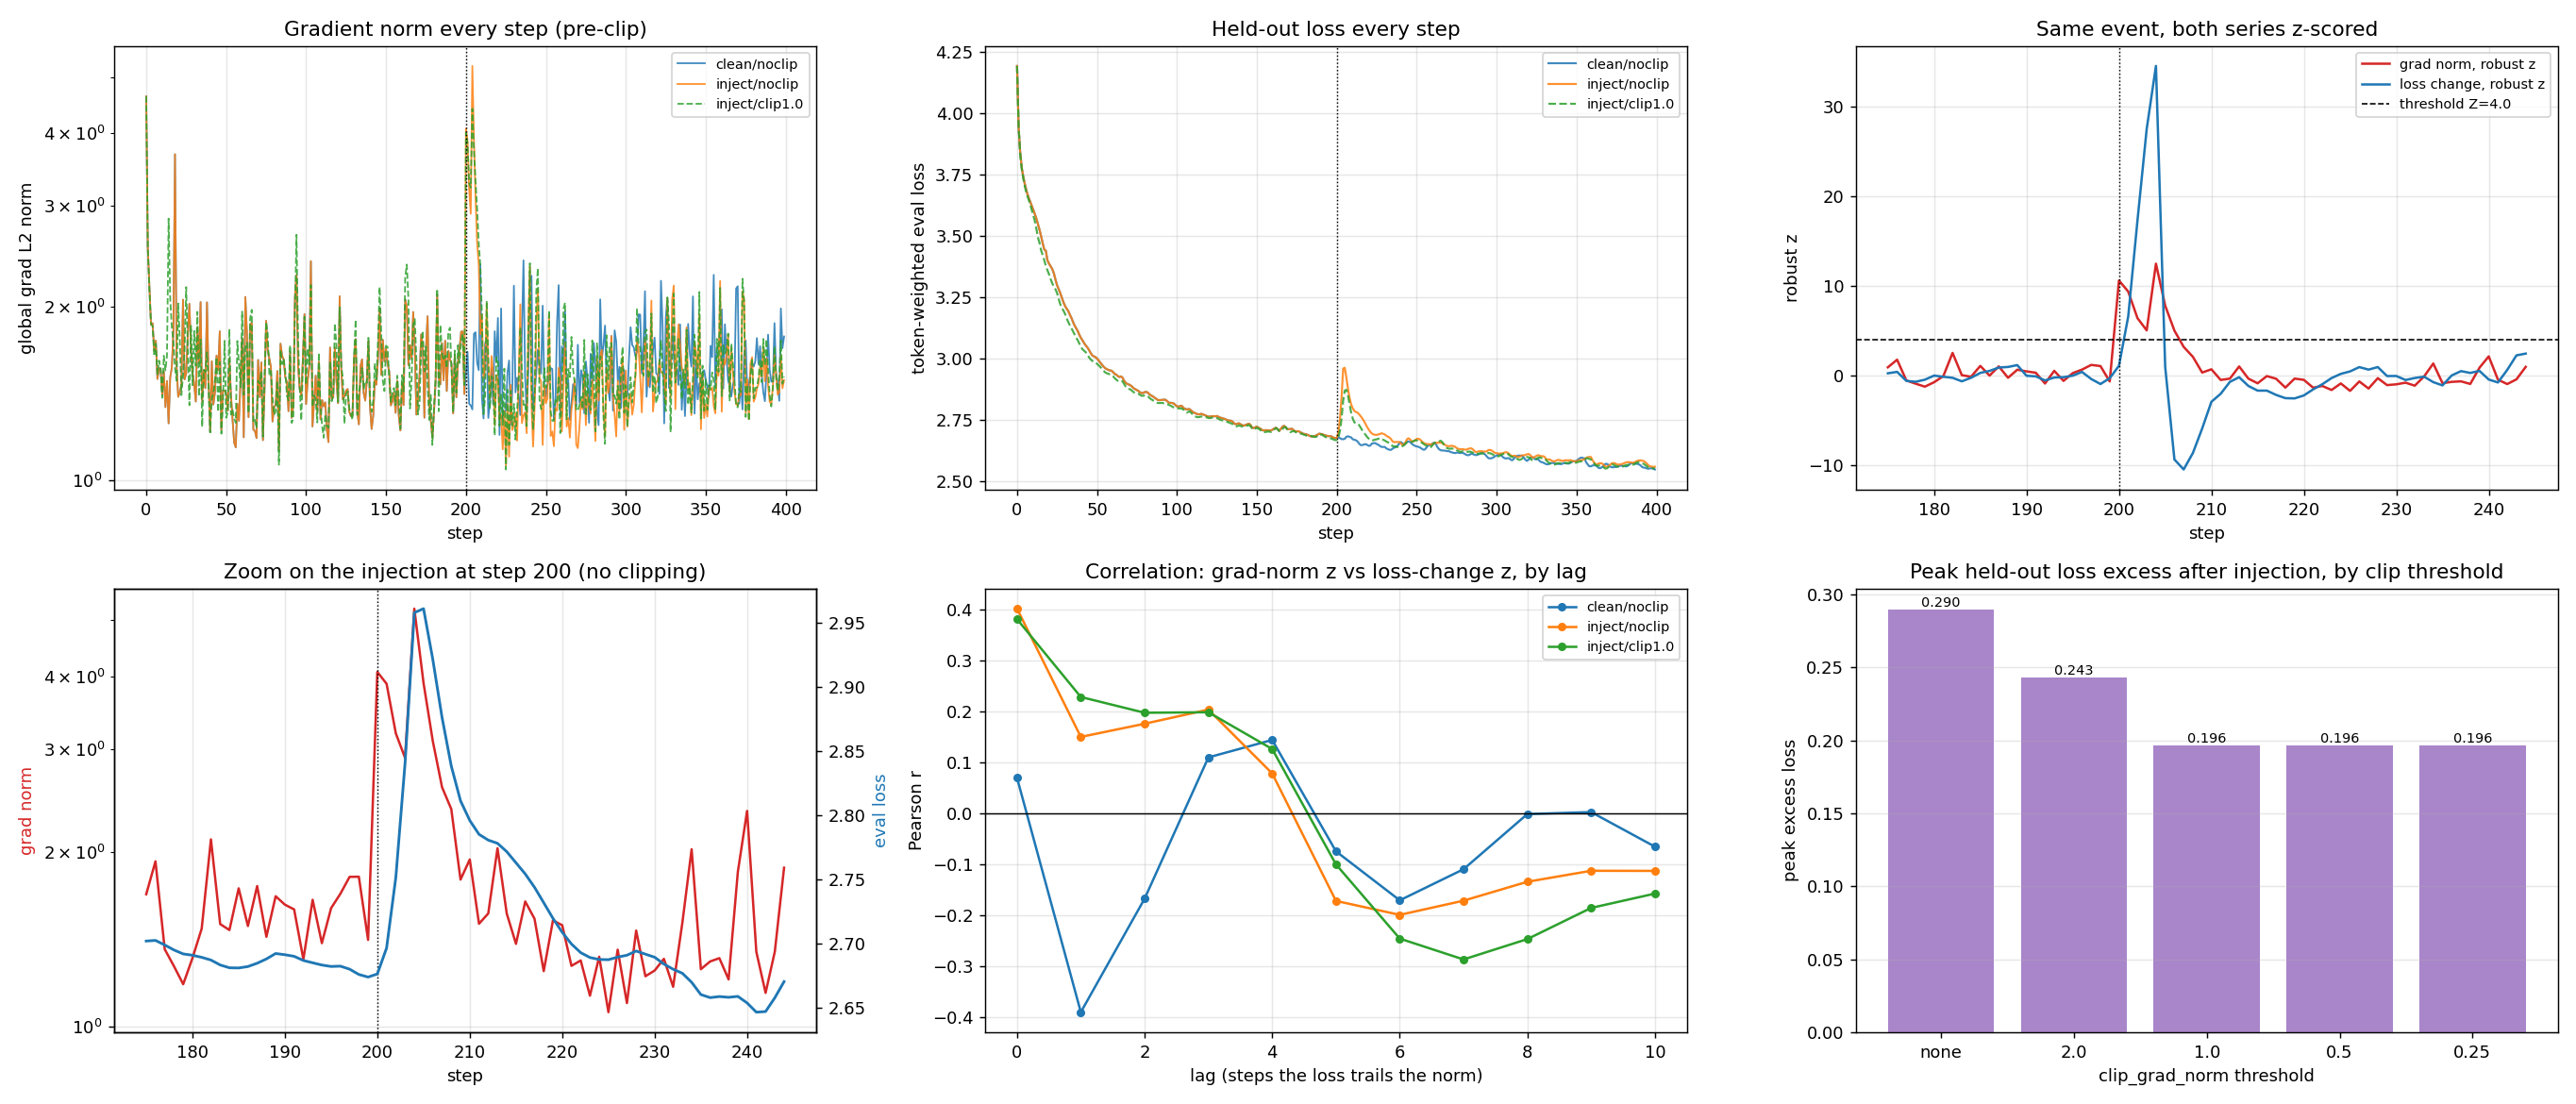

In [16]:
display(Image(filename=str(ROOT / "figures" / "t4_gradnorm.png")))

## Task 5 - MFU, honestly

Two choices keep the number from flattering itself. The denominator is
*measured* - the best rate this machine sustains on a large matmul in the
training dtype, benchmarked in-process - rather than a spec-sheet peak whose
value depends on which dtype and sparsity footnote you picked. And the
numerator is reported under both FLOP conventions: the strict `6N` the brief
asked for, and `6N` plus the attention term, since the score and value matmuls
involve no parameters at all.

In [17]:
t5 = art("t5_mfu.json")
h5 = t5["headline"]
print(f"device {t5['environment']['device']}, dtype {t5['environment']['dtype']}, "
      f"{t5['environment']['torch_threads']} thread(s)")
print(f"sustained peak       {h5['sustained_peak_gflops']:.1f} GFLOP/s")
print(f"throughput           {h5['tokens_per_second']:,.0f} tokens/s")
print(f"MFU (6N)             {h5['measured_mfu_6N']*100:.1f}%")
print(f"MFU (6N + attention) {h5['measured_mfu_6N_plus_attention']*100:.1f}%")
print(f"\nover {t5['repeatability']['trials']} identical runs: "
      f"{h5['mfu_6N_mean_over_trials']*100:.1f}% +/- "
      f"{h5['mfu_6N_std_over_trials']*100:.1f} "
      f"(spread {h5['mfu_6N_spread_pp']:.1f} pp)")
print("this is the one wall-clock section; everything else here is seed-deterministic")

device cpu, dtype torch.float32, 1 thread(s)
sustained peak       148.0 GFLOP/s
throughput           9,430 tokens/s
MFU (6N)             31.0%
MFU (6N + attention) 33.5%

over 4 identical runs: 29.6% +/- 0.5 (spread 1.1 pp)
this is the one wall-clock section; everything else here is seed-deterministic


Where the distance to 40% goes, measured rather than guessed:

In [18]:
for k, v in t5["attribution"]["budget"].items():
    print(f"{k}: {v['mfu_lost_pp']:.1f} percentage points")
    print(f"    {v['explanation']}")
print(f"\nMFU by configuration:")
for r in t5["size_sweep"]:
    print(f"  n_embd {r['n_embd']:>3}  L {r['n_layer']}  B {r['batch_rows']:>2}  "
          f"{r['n_params']/1e6:>6.2f}M params   MFU {r['mfu_6N']*100:>6.2f}%")

1_small_gemm_shapes: 34.1 percentage points
    the model's real matmul shapes reach only this fraction of the machine's large-GEMM rate
2_time_not_spent_in_matmuls: 4.5 percentage points
    optimizer step and batch preparation, measured
3_residual: 30.4 percentage points
    elementwise work counted in neither the 6N FLOP model nor the GEMM benchmark: LayerNorm, GELU, softmax, the causal mask, residual adds, plus kernel launch and memory traffic

MFU by configuration:
  n_embd 128  L 4  B  8    0.81M params   MFU  22.54%
  n_embd 128  L 4  B 32    0.81M params   MFU  29.88%
  n_embd 256  L 4  B  8    3.19M params   MFU  40.85%
  n_embd 256  L 4  B 32    3.19M params   MFU  49.23%
  n_embd 384  L 6  B  8   10.70M params   MFU  46.56%
  n_embd 384  L 6  B 32   10.70M params   MFU  57.96%
  n_embd 512  L 6  B  8   18.98M params   MFU  52.41%
  n_embd 512  L 6  B 32   18.98M params   MFU  64.84%


The session's own V4 figure is worth recomputing, because the transcript is
internally inconsistent: it reads *6848 teraflops achieved against 7912 peak*
for *8.2% MFU*, and 6848/7912 is 87%. Recomputing from the stated model size
and throughput settles it.

In [19]:
ref = t5["instructor_v4_reference"]
print(f"6 x {ref['params']:.0e} params x {ref['tokens_per_second']:,} tok/s "
      f"= {ref['achieved_tflops_per_s']:.0f} TFLOP/s")
print(f"{ref['achieved_tflops_per_s']:.0f} / "
      f"{ref['cluster_peak_flops_per_s']/1e12:.0f} = {ref['mfu']*100:.1f}%")
print(f"quoted in the session: {ref['session_quoted_mfu']*100:.1f}%  -> "
      f"reproduces: {ref['reproduces_quoted_value']}")
print("so the 6848 is a transcription slip for 648, and the formula is exact.")

6 x 9e+09 params x 12,000 tok/s = 648 TFLOP/s
648 / 7912 = 8.2%
quoted in the session: 8.2%  -> reproduces: True
so the 6848 is a transcription slip for 648, and the formula is exact.


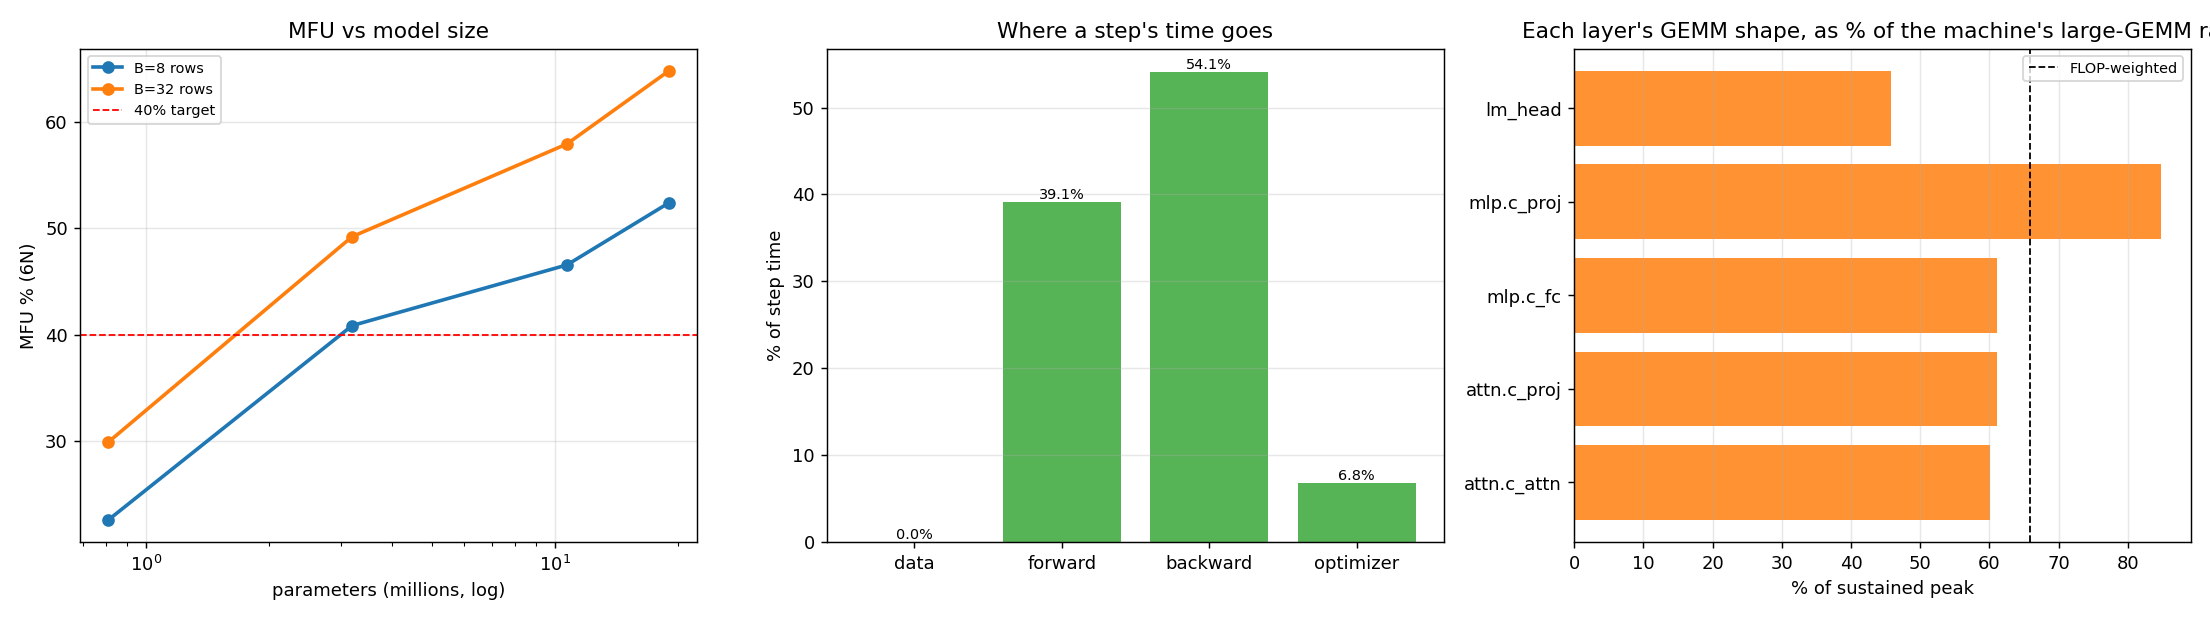

In [20]:
display(Image(filename=str(ROOT / "figures" / "t5_mfu.png")))

## Task 6 - 0.1, bit by bit

`0.1` is a good choice of number precisely because it is awkward. `1/10` has a
factor of 5 in the denominator and no power of 2 clears it, so the binary
expansion never terminates and **no** binary format stores it exactly. `0.5`
would have taught us nothing.

The bits below are derived from the definition of each format using exact
rational arithmetic - long division, normalisation, round-to-nearest-even - and
only *then* compared against what PyTorch actually stores, as a check rather
than as the source.

In [21]:
from fractions import Fraction
import t6_floats as F
print("0.1 in binary:")
print("  0." + F.binary_expansion(Fraction(1,10), 40) + " ...")
print("  = 1.100110011001100... x 2^-4   (the block 0011 repeats forever)")

0.1 in binary:
  0.0001100110011001100110011001100110011001 ...
  = 1.100110011001100... x 2^-4   (the block 0011 repeats forever)


In [22]:
t6 = art("t6_floats.json")
print(f"{'format':<10}{'s':>2} {'exponent':<10} {'mantissa':<25}"
      f"{'stored':>21}{'err %':>9}")
for name, e in t6["encodings"].items():
    print(f"{name:<10}{e['sign_bit']:>2} {e['exponent_bits']:<10} "
          f"{e['mantissa_bits']:<25}{e['stored_value']:>21.18f}"
          f"{e['relative_error_percent']:>9.4f}")
print(f"\nhand-derived bits match PyTorch for every format: "
      f"{t6['all_hand_encodings_match_pytorch']}")

format     s exponent   mantissa                                stored    err %
fp32       0 01111011   10011001100110011001101   0.100000001490116119   0.0000
fp16       0 01011      1001100110                0.099975585937500000   0.0244
bf16       0 01111011   1001101                   0.100097656250000000   0.0977
fp8_e4m3   0 0011       101                       0.101562500000000000   1.5625

hand-derived bits match PyTorch for every format: True


Working E4M3 through by hand, since it is the one worth being able to do:

    0.1 = 1.100110011... x 2^-4
    exponent: -4 + bias 7 = 3        -> 0011
    mantissa: 3 bits of 100|1100...  -> the next bit is 1 and the tail is
                                        non-zero, so round up -> 101
    significand 1.101b = 1.625,  1.625 x 2^-4 = 0.1015625

    bits  0 0011 101      error 1.5625%

Now the part that decides the answer. Casting this repo's own measured
gradients into each format:

In [23]:
g = t6["gradient_experiment"]
gs = g["gradient_stats"]
print(f"gradient magnitudes span {gs['dynamic_range_orders_of_magnitude']:.1f} "
      f"orders of magnitude ({gs['abs_min_nonzero']:.2e} to {gs['abs_max']:.2e})\n")
print(f"{'format':<18}{'flushed to zero':>18}{'median rel err':>18}")
for name, r in g["per_format"].items():
    print(f"{name:<18}{r['fraction_flushed_to_zero']*100:>17.4f}%"
          f"{r['median_relative_error']*100:>17.4f}%")
for name, r in g["with_global_scaling"].items():
    print(f"{name+' + scaling':<18}{r['fraction_flushed_to_zero']*100:>17.4f}%"
          f"{r['median_relative_error']*100:>17.4f}%")

gradient magnitudes span 13.6 orders of magnitude (1.42e-14 to 5.50e-01)

format               flushed to zero    median rel err
fp16                         0.0782%           0.0192%
bf16                         0.0000%           0.1350%
fp8_e4m3                    46.4433%          15.2608%
fp16 + scaling               0.0058%           0.0170%
fp8_e4m3 + scaling           1.2012%           2.3620%


### Which one would I train in

**bf16 for the training compute, with an fp32 master copy of the weights and
fp32 optimizer state.**

The reason is in the table above, not in the bit widths. fp16 is *more precise*
than bf16 at 0.1 - 0.024% error against 0.098% - and that does not help it,
because precision is not the binding constraint. Range is. These gradients span
13.6 orders of magnitude, and fp16's smallest normal is 6.1e-5 against bf16's
1.18e-38. bf16 spends its bits on the exponent, keeps fp32's entire range, and
flushed **zero** gradients. fp16 flushed some. A gradient rounded slightly wrong
still points the right way; a gradient rounded to zero is a parameter that
stopped learning, and you find out weeks later.

fp8 E4M3 raw is not usable: **46%** of these gradients go to zero and the median
survivor is off by 15%. But that is a fixable framing problem, not a verdict on
the format. One global scale factor before the cast and its inverse after takes
it to 1.2% flushed and 2.4% median error - which is the trick the session
described, and what NVIDIA's transformer engine does per tensor. fp8 is a
throughput win worth taking *with* that machinery, and a way to lose a training
run without it.

The fp32 master copy is not optional either, and Task 2 is the evidence: the
finite-difference check that reached 8-10 digits in fp64 collapsed to under one
digit in fp32. Small updates repeatedly accumulated into a low-precision
accumulator lose exactly that way.

### Does the recommendation survive an actual training run?

Everything above is a snapshot of one step's gradients, and a snapshot cannot
answer "would you *train* in it". Rounding that looks harmless once can
accumulate over thousands of steps, which is the entire reason the recipe keeps
an fp32 master copy. So it is run rather than asserted: three arms, same seed,
same data, all three evaluated in fp32 so they are scored on the same ruler.

In [24]:
t6b = art("t6b_bf16_train.json")
h6 = t6b["headline"]
print(f"{'arm':<28}{'final held-out loss':>20}{'max gap vs fp32':>18}")
print(f"{'fp32 (reference)':<28}{h6['fp32_final']:>20.6f}{'-':>18}")
print(f"{'bf16 compute + fp32 master':<28}{h6['bf16_autocast_final']:>20.6f}"
      f"{h6['bf16_autocast_max_gap']:>18.6f}")
print(f"{'pure bf16, no master copy':<28}{h6['pure_bf16_final']:>20.6f}"
      f"{h6['pure_bf16_max_gap']:>18.6f}")
print(f"\ndropping the master copy costs {h6['penalty_ratio']:.0f}x more drift")

arm                          final held-out loss   max gap vs fp32
fp32 (reference)                        2.441019                 -
bf16 compute + fp32 master              2.441318          0.000305
pure bf16, no master copy               2.461620          0.028559

dropping the master copy costs 94x more drift


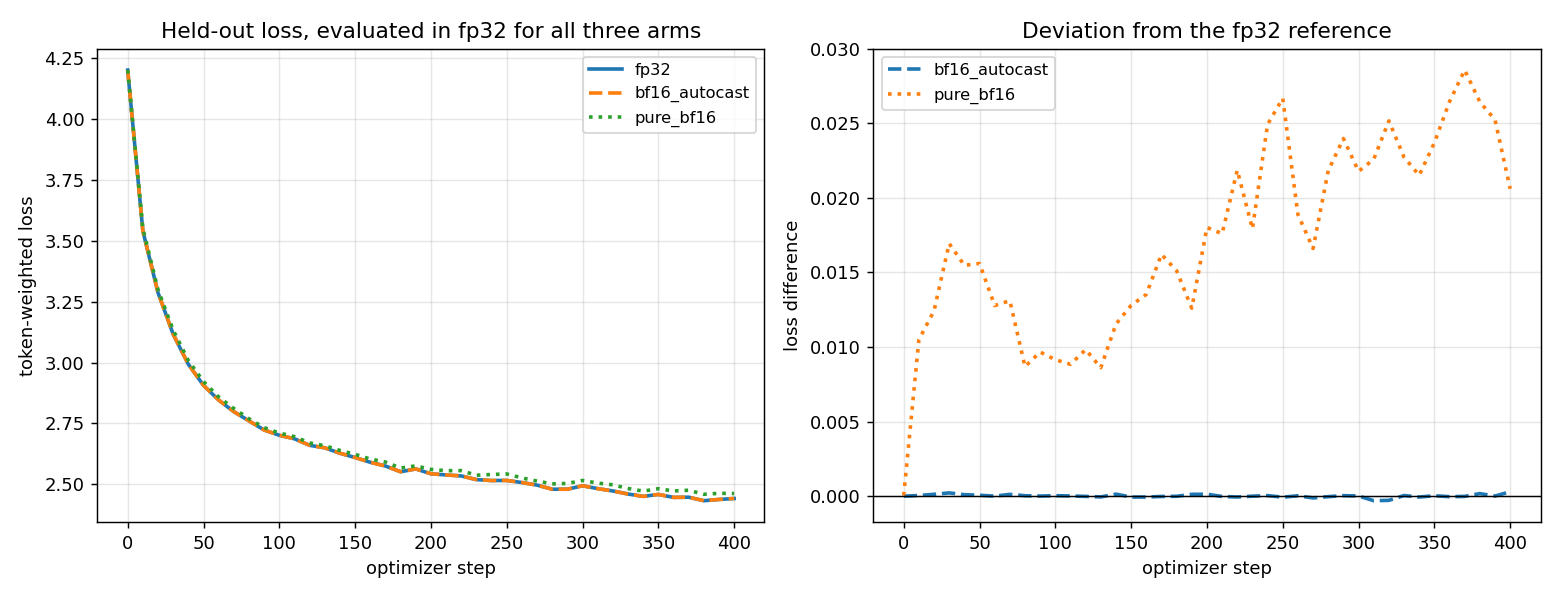

In [25]:
display(Image(filename=str(ROOT / "figures" / "t6b_bf16_train.png")))

## What this cost, and what it did not settle

Everything here ran on one CPU core. That is honest about some things and
misleading about others.

Honest: the shapes, the gradient check, the accumulation bug and its control,
the grad-norm lead, and every bit pattern are hardware-independent. They would
read the same on a B200.

Misleading: the MFU number. 28.65% of a single-thread CPU's matmul rate is not
the same statement as 28.65% of an H100, and the size sweep clearing 40% at 3.2M
parameters would look different on a device with tensor cores and real memory
bandwidth. `src/t5_mfu.py` is device-agnostic; running it on a GPU regenerates
every figure in that section.

Not settled: whether the accumulation bug's 0.018 loss gap compounds over a real
training run or stays bounded. 400 steps of an 810k-parameter model cannot
answer that, and I have not claimed it does.